# Indian Air Quality Analysis Using Python

## Project Overview

This project analyzes air quality data collected from different cities across India using Python and Pandas.

The main objective is to understand pollution levels, identify patterns in air quality, handle missing values using mean imputation, and generate meaningful insights through data analysis and visualization.

## Tools and Technologies
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn

## Objectives
1. Read and understand a CSV dataset.
2. Perform data cleaning and transformation.
3. Identify and handle missing values using mean imputation wherever applicable.
4. Analyze air pollution levels across Indian cities.
5. Generate meaningful insights.
6. Visualize the results using appropriate charts.

## Dataset
Air Quality Data in India (2015–2020).

## Expected Outcome
To understand air pollution patterns across Indian cities and communicate the findings using statistical analysis and visualizations.

In [1]:
from google.colab import files
upload =files.upload()

Saving city_day.csv.zip to city_day.csv (1).zip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
import zipfile

with zipfile.ZipFile('city_day.csv.zip', 'r') as zip_ref:
    zip_ref.extractall()

In [8]:
import pandas as pd
df = pd.read_csv('city_day.csv')
df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [9]:
print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)
print("Column names:")
print(df.columns)
print("First 5 rows:")
display(df.head())

Dataset loaded successfully!
Shape of dataset: (29531, 16)
Column names:
Index(['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket'],
      dtype='object')
First 5 rows:


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [10]:
df.shape

(29531, 16)

In [11]:
df.columns

Index(['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket'],
      dtype='object')

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: float64(13), object(3)
memory usage: 3.6+ MB


In [13]:
df.describe()

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,24933.000000,18391.000000,25949.000000,25946.000000,25346.000000,19203.000000,27472.000000,25677.000000,25509.000000,23908.000000,21490.000000,11422.000000,24850.000000
mean,67.450578,118.127103,17.574730,28.560659,32.309123,23.483476,2.248598,14.531977,34.491430,3.280840,8.700972,3.070128,166.463581
std,64.661449,90.605110,22.785846,24.474746,31.646011,25.684275,6.962884,18.133775,21.694928,15.811136,19.969164,6.323247,140.696585
min,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,28.820000,56.255000,5.630000,11.750000,12.820000,8.580000,0.510000,5.670000,18.860000,0.120000,0.600000,0.140000,81.000000
50%,48.570000,95.680000,9.890000,21.690000,23.520000,15.850000,0.890000,9.160000,30.840000,1.070000,2.970000,0.980000,118.000000
75%,80.590000,149.745000,19.950000,37.620000,40.127500,30.020000,1.450000,15.220000,45.570000,3.080000,9.150000,3.350000,208.000000
max,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000


In [14]:
df.isnull().sum()

,0
City,0
Date,0
PM2.5,4598
PM10,11140
NO,3582
NO2,3585
NOx,4185
NH3,10328
CO,2059
SO2,3854


In [15]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage)

City           0.000000
Date           0.000000
PM2.5         15.570079
PM10          37.723071
NO            12.129626
NO2           12.139785
NOx           14.171549
NH3           34.973418
CO             6.972334
SO2           13.050692
O3            13.619586
Benzene       19.041008
Toluene       27.229014
Xylene        61.322001
AQI           15.851139
AQI_Bucket    15.851139
dtype: float64


In [16]:
df_original = df.copy()
print("Original dataset backup created!")

Original dataset backup created!


In [17]:
df['Date'] = pd.to_datetime(df['Date'])
print(df['Date'].dtype)

datetime64[ns]


In [18]:
df['Year'] = df['Date'].dt.year
df[['Date', 'Year']].head()

,Date,Year
0,2015-01-01,2015
1,2015-01-02,2015
2,2015-01-03,2015
3,2015-01-04,2015
4,2015-01-05,2015


In [19]:
df['Month'] = df['Date'].dt.month
df[['Date', 'Month']].head()

,Date,Month
0,2015-01-01,1
1,2015-01-02,1
2,2015-01-03,1
3,2015-01-04,1
4,2015-01-05,1


In [20]:
df['Month_Name'] = df['Date'].dt.month_name()
df[['Date', 'Month', 'Month_Name']].head()

,Date,Month,Month_Name
0,2015-01-01,1,January
1,2015-01-02,1,January
2,2015-01-03,1,January
3,2015-01-04,1,January
4,2015-01-05,1,January


In [21]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [22]:
df = df.drop_duplicates()
print("Duplicates removed successfully!")

Duplicates removed successfully!


In [23]:
print("Updated Dataset Shape:", df.shape)
print("\nUpdated Column Names:")
print(df.columns)
df.head()

Updated Dataset Shape: (29531, 19)

Updated Column Names:
Index(['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket', 'Year',
       'Month', 'Month_Name'],
      dtype='object')


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket,Year,Month,Month_Name
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN,2015,1,January
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN,2015,1,January
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN,2015,1,January
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN,2015,1,January
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN,2015,1,January


In [24]:
df.isnull().sum()

,0
City,0
Date,0
PM2.5,4598
PM10,11140
NO,3582
NO2,3585
NOx,4185
NH3,10328
CO,2059
SO2,3854


In [25]:
numeric_columns = df.select_dtypes(include=np.number).columns
print(numeric_columns)

Index(['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3',
       'Benzene', 'Toluene', 'Xylene', 'AQI', 'Year', 'Month'],
      dtype='object')


In [26]:
df[numeric_columns].mean()

,0
PM2.5,67.450578
PM10,118.127103
NO,17.574730
NO2,28.560659
NOx,32.309123
NH3,23.483476
CO,2.248598
SO2,14.531977
O3,34.491430
Benzene,3.280840


In [27]:
pollutant_columns = [
    'PM2.5', 'PM10', 'NO', 'NO2',
    'NOx', 'NH3', 'CO', 'SO2', 'O3',
    'Benzene', 'Toluene', 'Xylene', 'AQI'
]
for col in pollutant_columns:
    df[col] = df.groupby('City')[col].transform(
        lambda x: x.fillna(x.mean())
    )

In [28]:
print(df.isnull().sum())

City              0
Date              0
PM2.5             0
PM10           2009
NO                0
NO2               0
NOx            1169
NH3            2009
CO                0
SO2               0
O3              162
Benzene        2732
Toluene        4010
Xylene        13047
AQI               0
AQI_Bucket     4681
Year              0
Month             0
Month_Name        0
dtype: int64


In [29]:
df.isnull().sum()

,0
City,0
Date,0
PM2.5,0
PM10,2009
NO,0
NO2,0
NOx,1169
NH3,2009
CO,0
SO2,0


In [30]:
city_aqi = df.groupby('City')['AQI'].mean().sort_values(ascending=False)
print("Average AQI by City:")
display(city_aqi)

Average AQI by City:


,AQI
City,
Ahmedabad,452.122939
Delhi,259.487744
Patna,240.782042
Gurugram,225.123882
Lucknow,217.973059
Talcher,172.886819
Jorapokhar,159.251621
Brajrajnagar,150.280505
Kolkata,140.566313


In [31]:
print("City with highest average AQI:")
print(city_aqi.idxmax())
print("Highest average AQI:")
print(city_aqi.max())

City with highest average AQI:
Ahmedabad
Highest average AQI:
452.12293853073464


In [32]:
print("City with lowest average AQI:")
print(city_aqi.idxmin())
print("Lowest average AQI:")
print(city_aqi.min())

City with lowest average AQI:
Aizawl
Lowest average AQI:
34.765765765765764


In [33]:
yearly_aqi = df.groupby('Year')['AQI'].mean()
print("Yearly Average AQI:")
display(yearly_aqi)

Yearly Average AQI:


,AQI
Year,
2015,199.132393
2016,205.102639
2017,190.261521
2018,178.325787
2019,155.379158
2020,114.282183


In [34]:
monthly_aqi = df.groupby('Month_Name')['AQI'].mean()
month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]
monthly_aqi = monthly_aqi.reindex(month_order)
display(monthly_aqi)

,AQI
Month_Name,
January,225.546280
February,201.256037
March,167.686823
April,149.113975
May,144.272968
June,131.839786
July,124.426822
August,124.878914
September,127.530941


In [35]:
print("Month with highest average AQI:")
print(monthly_aqi.idxmax())
print("Average AQI:")
print(monthly_aqi.max())

Month with highest average AQI:
November
Average AQI:
235.01282696152882


In [36]:
pollutants = [
    'PM2.5', 'PM10', 'NO', 'NO2',
    'NOx', 'NH3', 'CO', 'SO2', 'O3'
]
pollutant_average = df[pollutants].mean()
print("Average pollutant concentrations:")
display(pollutant_average.sort_values(ascending=False))

Average pollutant concentrations:


,0
PM10,116.228087
PM2.5,66.234841
O3,34.329319
NOx,32.855058
NO2,28.641768
NH3,23.024137
NO,18.226745
SO2,15.639939
CO,2.602122


In [37]:
correlation = df['PM2.5'].corr(df['AQI'])
print("Correlation between PM2.5 and AQI:", correlation)

Correlation between PM2.5 and AQI: 0.6101639929518655


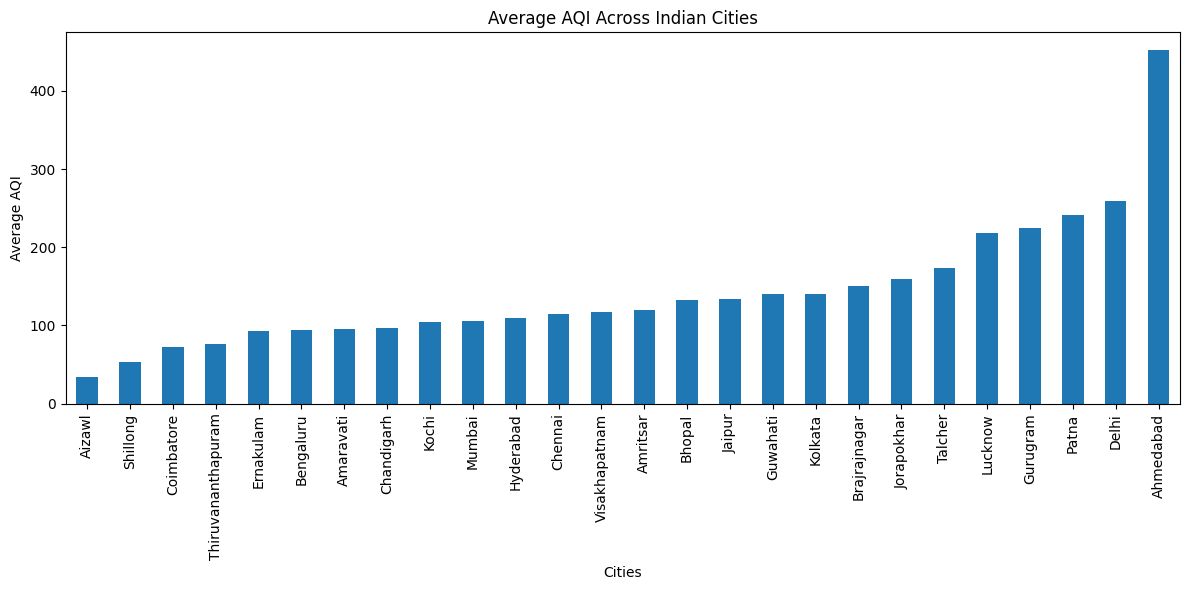

In [38]:
plt.figure(figsize=(12,6))
city_aqi.sort_values().plot(kind='bar')
plt.title('Average AQI Across Indian Cities')
plt.xlabel('Cities')
plt.ylabel('Average AQI')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

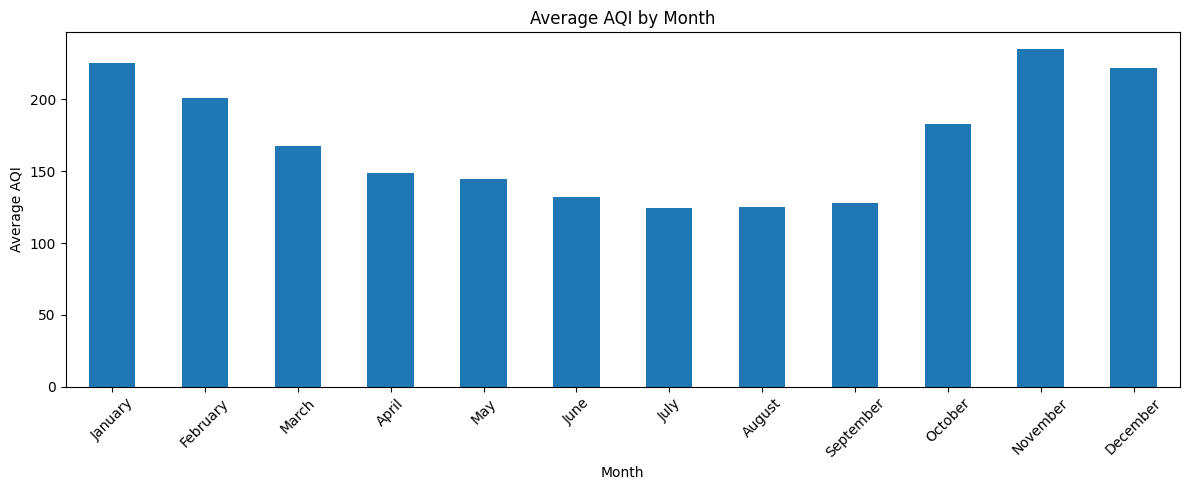

In [39]:
plt.figure(figsize=(12,5))
monthly_aqi.plot(kind='bar')
plt.title('Average AQI by Month')
plt.xlabel('Month')
plt.ylabel('Average AQI')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

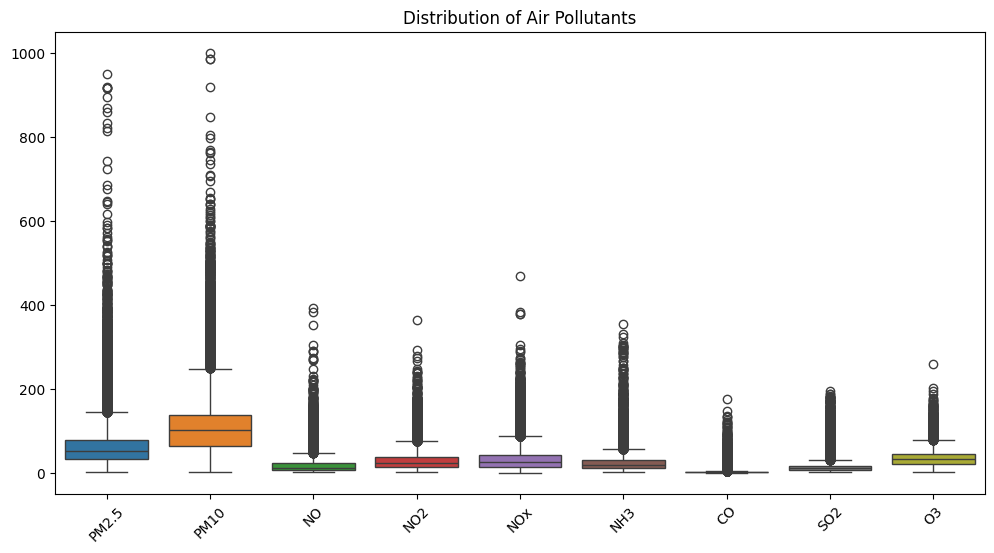

In [41]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df[pollutants])
plt.title('Distribution of Air Pollutants')
plt.xticks(rotation=45)
plt.show()

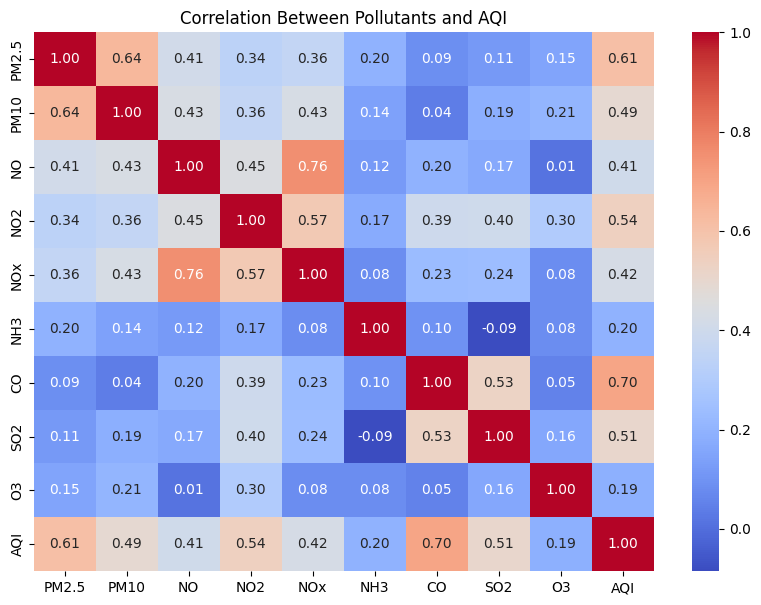

In [42]:
plt.figure(figsize=(10,7))
sns.heatmap(
    df[pollutants + ['AQI']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Between Pollutants and AQI')
plt.show()

# Conclusion

The Indian Air Quality dataset was analyzed using Python and Pandas.

During this project, data understanding, data transformation, missing value identification, and mean imputation were performed.

Different insights were generated to understand:
- Differences in average AQI across cities.
- Changes in AQI over different years.
- Monthly pollution patterns.
- Distribution of different air pollutants.
- Relationships between pollutants and AQI.

Various visualizations, including bar charts, line graphs, box plots, and correlation heatmaps, were created to represent the findings.

This project helped demonstrate how Python and data analysis techniques can be used to understand real-world environmental data and identify meaningful patterns.